# Dataset inventory
This notebook reads the reproducible bounded dataset output; it does not download archives.

In [1]:
import json
from pathlib import Path
import pandas as pd
root = Path('../data/research_dataset')
version = json.loads((root / 'dataset_version_manifest.json').read_text())
manifest = pd.read_parquet(root / 'manifests/unified_manifest.parquet')
print(json.dumps(version['result']['valid_paired_counts'], indent=2))
display(manifest.groupby(['source_dataset', 'task_type', 'download_status']).size().rename('rows').reset_index())

{
  "Fakeddit": 4233,
  "NewsCLIPpings": 0
}


,source_dataset,task_type,download_status,rows
0,Fakeddit,fake_news_classification,verified_reused_or_processed,4233
1,NewsCLIPpings,image_caption_mismatch,blocked_missing_visualnews_metadata_and_image,1430560


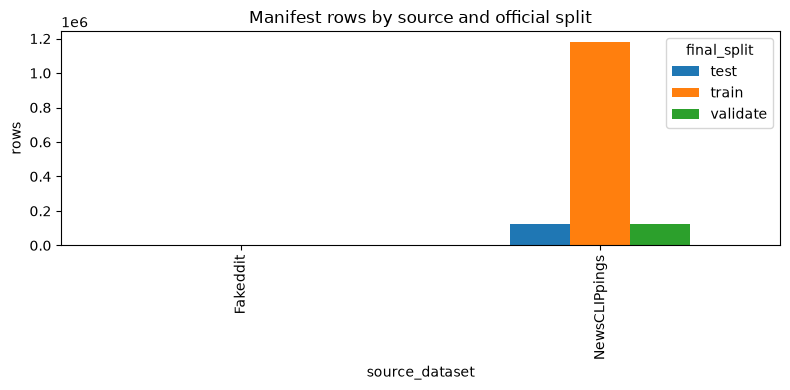

In [2]:
import matplotlib.pyplot as plt
counts = manifest.groupby(['source_dataset', 'final_split']).size().unstack(fill_value=0)
counts.plot(kind='bar', figsize=(8, 4), title='Manifest rows by source and official split')
plt.ylabel('rows'); plt.tight_layout(); plt.show()